In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

Matplotlib is building the font cache; this may take a moment.


In [3]:
df = pd.read_csv("nhanes_phase1_data.csv")

In [4]:
print("ابعاد مجموعه داده (سطر، ستون):", df.shape)

print("\nتعداد مقادیر گمشده در هر ستون:")
print(df.isnull().sum())

ابعاد مجموعه داده (سطر، ستون): (500, 7)

تعداد مقادیر گمشده در هر ستون:
SEQN               0
Age                0
Age_Group          0
Gender             0
Smoking_Status     0
Systolic_BP       16
WTMEC2YR           0
dtype: int64


In [5]:
print("\n--- جدول فراوانی وضعیت دخانیات ---")

freq = pd.crosstab(
    index=df['Smoking_Status'],
    columns='تعداد',
    margins=True
)

freq['درصد'] = (
    freq['تعداد'] / df['Smoking_Status'].notna().sum()
) * 100

print(freq)


--- جدول فراوانی وضعیت دخانیات ---
col_0           تعداد  All   درصد
Smoking_Status                   
Non-Smoker        394  394   78.8
Smoker            106  106   21.2
All               500  500  100.0


In [6]:
print("\n--- شاخص‌های توصیفی فشار خون سیستولیک ---")

stats = df.groupby('Smoking_Status')['Systolic_BP'].describe()

stats['IQR'] = stats['75%'] - stats['25%']

print(stats[['count', 'mean', 'std', '50%', 'IQR', 'min', 'max']])


--- شاخص‌های توصیفی فشار خون سیستولیک ---
                count        mean        std    50%    IQR   min    max
Smoking_Status                                                         
Non-Smoker      381.0  120.604462  12.518025  120.8  15.70  79.5  153.7
Smoker          103.0  126.289320  10.968117  126.4  13.85  98.4  148.6


In [8]:
unweighted_mean = df['Systolic_BP'].mean()

weighted_mean = np.average(
    df['Systolic_BP'].dropna(),
    weights=df.loc[
        df['Systolic_BP'].notnull(),
        'WTMEC2YR'
    ]
)

print(f"\nمیانگین بدون وزن فشار خون: {unweighted_mean:.2f} mmHg")

print(f"میانگین وزن‌دار واقعی جامعه: {weighted_mean:.2f} mmHg")


میانگین بدون وزن فشار خون: 121.81 mmHg
میانگین وزن‌دار واقعی جامعه: 121.98 mmHg


C:\Users\kavosh\AppData\Local\Temp\ipykernel_16892\1192602053.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


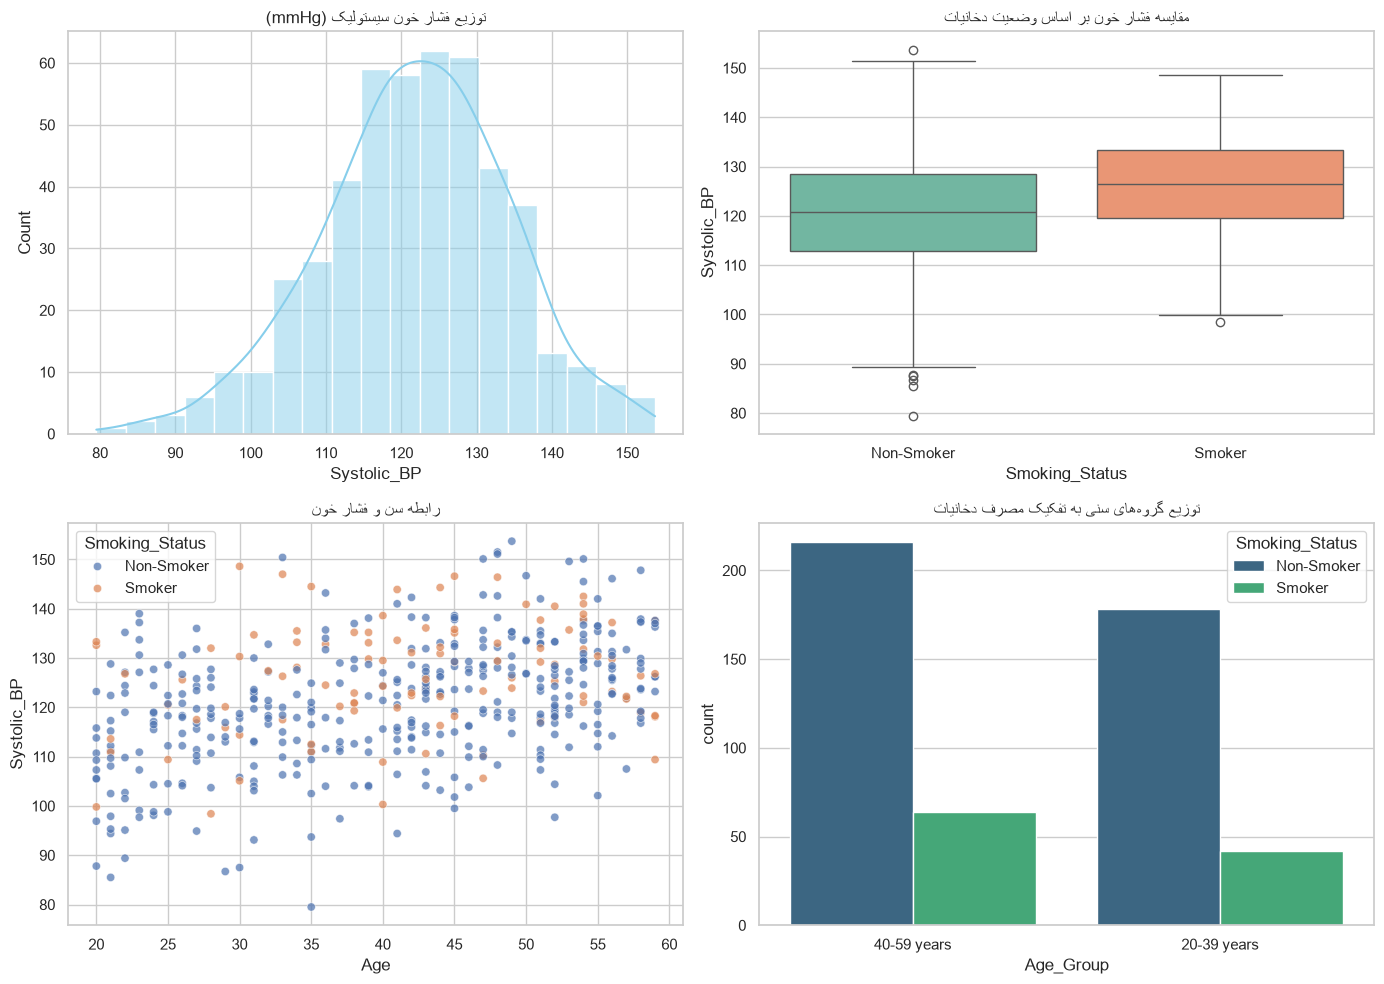

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histogram
sns.histplot(
    data=df,
    x='Systolic_BP',
    kde=True,
    ax=axes[0, 0],
    color='skyblue'
)
axes[0, 0].set_title('توزیع فشار خون سیستولیک (mmHg)')

# Boxplot
sns.boxplot(
    data=df,
    x='Smoking_Status',
    y='Systolic_BP',
    ax=axes[0, 1],
    palette='Set2'
)
axes[0, 1].set_title('مقایسه فشار خون بر اساس وضعیت دخانیات')

# Scatterplot
sns.scatterplot(
    data=df,
    x='Age',
    y='Systolic_BP',
    hue='Smoking_Status',
    alpha=0.7,
    ax=axes[1, 0]
)
axes[1, 0].set_title('رابطه سن و فشار خون')

# Countplot
sns.countplot(
    data=df,
    x='Age_Group',
    hue='Smoking_Status',
    ax=axes[1, 1],
    palette='viridis'
)
axes[1, 1].set_title('توزیع گروه‌های سنی به تفکیک مصرف دخانیات')

plt.tight_layout()
plt.savefig('phase1_plots.png', dpi=300)
plt.show()